In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA = Path("../data")
df = pd.read_csv(DATA / "merged_school_dataset.csv")

numeric_features = [
    "fsm_pct_2024", "imd_score", "income_score", "employment_score",
    "health_score", "crime_score", "barriers_score", "living_env_score",
    "idaci_score", "adult_skills_score", "geo_barriers_score",
    "wider_barriers_score", "indoors_score", "outdoors_score",
    "p8_2023", "a8_2024",
]

# Rebuild the exact same split used in ann_p8.ipynb
df_p8 = df.loc[df["p8_2024"].notna()].copy()
X_raw = df_p8[numeric_features]
y_raw = df_p8["p8_2024"].values

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=SEED)

imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()
X_train = scaler.fit_transform(imputer.fit_transform(X_train_raw))
X_test  = scaler.transform(imputer.transform(X_test_raw))

y_mean, y_std = y_train.mean(), y_train.std()

# Rebuild the model and load trained weights
class P8ANN(nn.Module):
    def __init__(self, n_features=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 32),         nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(32, 1),
        )
    def forward(self, x): return self.net(x)


model = P8ANN()
model.load_state_dict(torch.load("../models/p8_ann.pt"))
model.eval()
print("Model loaded. Test shape:", X_test.shape)

Model loaded. Test shape: (472, 16)


In [2]:
# SHAP needs a function that takes a numpy array and returns predictions
def predict_fn(X_numpy):
    with torch.no_grad():
        X_t = torch.FloatTensor(X_numpy)
        pred_scaled = model(X_t).numpy().ravel()
        pred = pred_scaled * y_std + y_mean   # de-standardise to A8 units
    return pred

# KernelExplainer works for any model but is slow — use a small background sample
# Background = reference set SHAP uses to compute baseline. 100 rows is plenty.
background = shap.sample(X_train, 100, random_state=SEED)

explainer = shap.KernelExplainer(predict_fn, background)
print("SHAP explainer created.")
print(f"Baseline (expected prediction): {explainer.expected_value:.2f}")

SHAP explainer created.
Baseline (expected prediction): 0.01


In [3]:
# Compute SHAP for a sample of test schools (full test set would take ~30 min)
# 100 schools gives representative patterns in about 3-5 minutes
n_explain = 100
X_explain = X_test[:n_explain]
shap_values = explainer.shap_values(X_explain, nsamples=100)

print(f"SHAP values shape: {shap_values.shape}")
# Should be (100, 16) — one row per school, one column per feature

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP values shape: (100, 16)


C:\Users\modne\AppData\Local\Temp\ipykernel_6836\1708008304.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


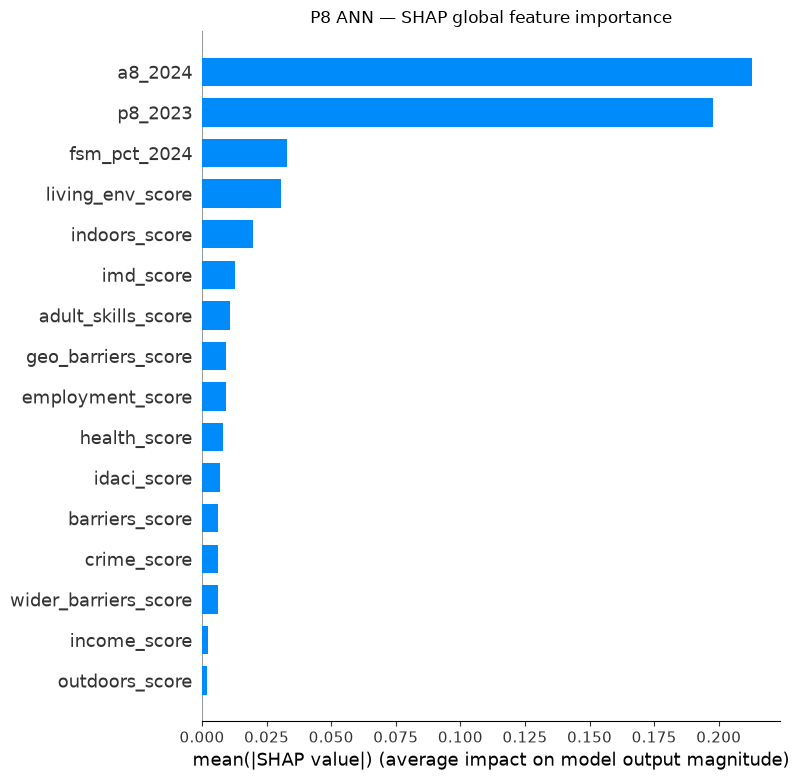

In [4]:
shap.summary_plot(
    shap_values, X_explain,
    feature_names=numeric_features,
    plot_type="bar",
    show=False,
)
plt.title("P8 ANN — SHAP global feature importance")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_p8_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\modne\AppData\Local\Temp\ipykernel_6836\1640803556.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


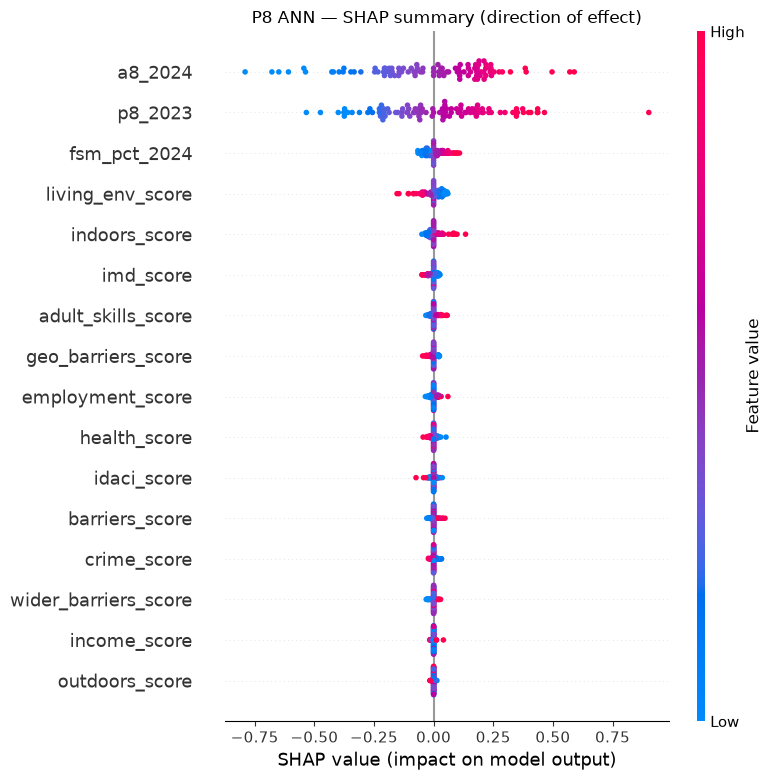

In [5]:
shap.summary_plot(
    shap_values, X_explain,
    feature_names=numeric_features,
    show=False,
)
plt.title("P8 ANN — SHAP summary (direction of effect)")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_p8_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

Schools in plot: 3,141
Pearson correlation (imd_score vs p8_2024): -0.190


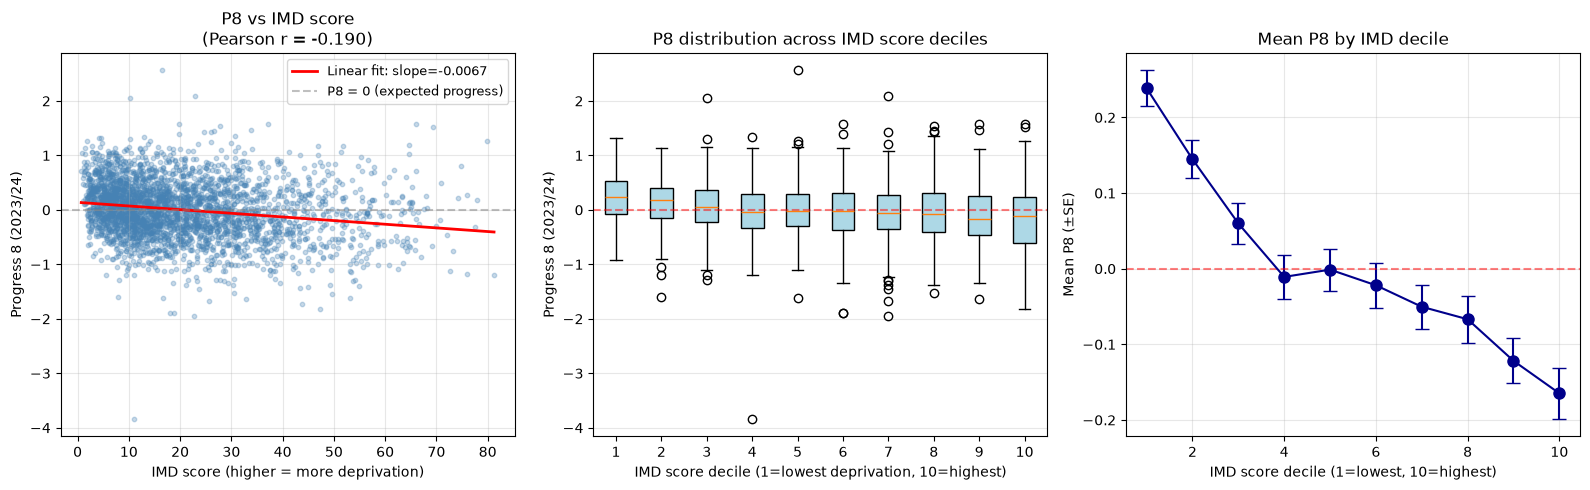


═══ P8 by IMD decile (1=lowest deprivation, 10=highest) ═══
                 mean    std  count
imd_decile_bin                     
1               0.239  0.417    315
2               0.145  0.452    314
3               0.060  0.477    314
4              -0.011  0.507    314
5              -0.001  0.493    314
6              -0.022  0.521    314
7              -0.050  0.517    314
8              -0.067  0.549    314
9              -0.122  0.526    314
10             -0.165  0.603    314


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

#Check SHAP analaysys vs actual IMD scores varies with P8

# Load the merged dataset (fresh — not standardised)
DATA = Path("../data")
df = pd.read_csv(DATA / "merged_school_dataset.csv")

# Keep only schools with both P8 and IMD available
df_plot = df.loc[df["p8_2024"].notna() & df["imd_score"].notna()].copy()
print(f"Schools in plot: {len(df_plot):,}")

# Compute Pearson correlation
r = df_plot[["imd_score", "p8_2024"]].corr().iloc[0, 1]
print(f"Pearson correlation (imd_score vs p8_2024): {r:.3f}")

# ─── Three-panel diagnostic ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Scatter plot with regression line
ax = axes[0]
ax.scatter(df_plot["imd_score"], df_plot["p8_2024"], alpha=0.3, s=10, color="steelblue")
# Add linear trend line
z = np.polyfit(df_plot["imd_score"], df_plot["p8_2024"], 1)
x_line = np.linspace(df_plot["imd_score"].min(), df_plot["imd_score"].max(), 100)
ax.plot(x_line, z[0] * x_line + z[1], "r-", linewidth=2, label=f"Linear fit: slope={z[0]:.4f}")
ax.axhline(y=0, color="grey", linestyle="--", alpha=0.5, label="P8 = 0 (expected progress)")
ax.set_xlabel("IMD score (higher = more deprivation)")
ax.set_ylabel("Progress 8 (2023/24)")
ax.set_title(f"P8 vs IMD score\n(Pearson r = {r:.3f})")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Panel 2: Boxplot by IMD decile
ax = axes[1]
# Bin IMD score into deciles
df_plot["imd_decile_bin"] = pd.qcut(df_plot["imd_score"], q=10, labels=range(1, 11))
box_data = [df_plot.loc[df_plot["imd_decile_bin"] == d, "p8_2024"].values for d in range(1, 11)]
bp = ax.boxplot(box_data, patch_artist=True, label=range(1, 11))
for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
ax.axhline(y=0, color="red", linestyle="--", alpha=0.5)
ax.set_xlabel("IMD score decile (1=lowest deprivation, 10=highest)")
ax.set_ylabel("Progress 8 (2023/24)")
ax.set_title("P8 distribution across IMD score deciles")
ax.grid(True, alpha=0.3, axis="y")

# Panel 3: Mean P8 per IMD decile with error bars
ax = axes[2]
decile_stats = df_plot.groupby("imd_decile_bin", observed=True)["p8_2024"].agg(["mean", "std", "count"])
ax.errorbar(decile_stats.index, decile_stats["mean"],
            yerr=decile_stats["std"] / np.sqrt(decile_stats["count"]),
            fmt="o-", capsize=5, color="darkblue", markersize=8)
ax.axhline(y=0, color="red", linestyle="--", alpha=0.5)
ax.set_xlabel("IMD score decile (1=lowest, 10=highest)")
ax.set_ylabel("Mean P8 (±SE)")
ax.set_title("Mean P8 by IMD decile")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../SRC/EDA/fig_p8_vs_imd_score.png", dpi=150, bbox_inches="tight")
plt.show()

# Print decile summary
print(f"\n═══ P8 by IMD decile (1=lowest deprivation, 10=highest) ═══")
print(decile_stats.round(3))